# RoboJEPA: Colab hardware, simulation, dataset, and baseline smoke test

This notebook turns the first two milestones from the **Language-Guided Robot Control with a JEPA World Model** proposal into one reproducible Colab run.

It verifies the runtime, exercises MuJoCo and robosuite offscreen rendering, builds a small leak-resistant pushing dataset, extracts frozen DINOv2 and sentence features, trains the direct and JEPA-style baselines, evaluates offline action ranking, and saves everything needed for the next stage.

### What this notebook does

1. Checks Python, PyTorch, GPU/CUDA, mixed precision, RAM, disk, and DataLoader workers.
2. Runs a direct MuJoCo render and a robosuite `Lift` rollout with camera observations.
3. Generates 100-500+ candidate push trajectories in a lightweight tabletop simulator.
4. Splits by starting scene and reserves paraphrases for test to avoid leakage.
5. Caches frozen DINOv2-small visual features and frozen text embeddings.
6. Trains:
   - a direct instruction-conditioned action classifier;
   - an action-conditioned JEPA predictor;
   - an instruction-conditioned terminal-feature scorer.
7. Compares direct, JEPA-predicted, and oracle-terminal action ranking.
8. Saves metadata, images, feature caches, checkpoints, metrics, plots, and a compatibility report.

> **Colab note:** choose **Runtime -> Change runtime type -> GPU** before running all cells. Colab validates the NVIDIA/CUDA path. It cannot validate the proposal's local AMD RX 9070 XT/ROCm stack; the PyTorch code below keeps device handling portable so it can be reused in a ROCm environment.


In [20]:
# 1. Install runtime dependencies (usually 1-3 minutes on a fresh Colab runtime)
import os
import sys
import subprocess
from importlib.metadata import PackageNotFoundError, version as distribution_version

# Must be set before importing mujoco / robosuite.
os.environ.setdefault("MUJOCO_GL", "egl")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

# Keep Colab's NumPy and pandas wheels together. Upgrading only NumPy can
# produce: 'numpy.dtype size changed, may indicate binary incompatibility'.
def installed_pin(package_name, fallback):
    try:
        return f"{package_name}=={distribution_version(package_name)}"
    except PackageNotFoundError:
        return fallback


NUMPY_PIN = installed_pin("numpy", "numpy>=1.26,<2.1")
PANDAS_PIN = installed_pin("pandas", "pandas>=2.2,<2.3")
print("Preserving runtime binary stack:", NUMPY_PIN, PANDAS_PIN)

PACKAGES = [
    NUMPY_PIN,
    PANDAS_PIN,
    "mujoco>=3.2,<4",
    "robosuite>=1.5,<1.6",
    "sentence-transformers>=3,<6",
    "scikit-learn>=1.3",
    "seaborn>=0.13",
    "psutil>=5.9",
    "imageio>=2.31",
    "tqdm>=4.66",
]

subprocess.check_call(
    [sys.executable, "-m", "pip", "install", "-q", *PACKAGES]
)

# Verify ABI compatibility in a clean interpreter before importing the stack below.
verification = subprocess.run(
    [
        sys.executable,
        "-c",
        "import numpy, pandas; print('NumPy', numpy.__version__, 'pandas', pandas.__version__)",
    ],
    text=True,
    capture_output=True,
)
if verification.returncode != 0:
    raise RuntimeError(
        "The current runtime already has an incompatible NumPy/pandas installation. "
        "In Colab choose Runtime > Disconnect and delete runtime, reconnect, "
        "then run this fixed notebook from the first cell.\n\n"
        + verification.stderr
    )
print(verification.stdout.strip())
print("Dependencies installed and binary imports verified.")


Preserving runtime binary stack: numpy==1.26.4 pandas==2.2.2
NumPy 1.26.4 pandas 2.2.2
Dependencies installed and binary imports verified.


## Run configuration

- `FAST_MODE=True` is the recommended first pass. It creates 144 candidate trajectories and uses short training runs.
- `FAST_MODE=False` creates 504 candidate trajectories and trains longer.
- Pretrained encoders are attempted by default. A deterministic offline fallback keeps the pipeline testable if model downloads fail.
- The optional DINOv2 last-block fine-tuning cell is intentionally disabled by default and isolated from the baseline comparison.


In [21]:
# 2. Reproducible configuration and imports
from __future__ import annotations

import copy
import json
import math
import platform
import random
import shutil
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import imageio.v2 as imageio
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import seaborn as sns
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageDraw
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm


@dataclass(frozen=True)
class Config:
    seed: int = 590
    fast_mode: bool = True
    image_size: int = 96
    candidates_per_scene: int = 6
    fast_scenes: int = 24       # 24 x 6 = 144 candidate trajectories
    full_scenes: int = 84       # 84 x 6 = 504 candidate trajectories
    fast_epochs: int = 12
    full_epochs: int = 30
    batch_size: int = 128
    use_pretrained_encoders: bool = True
    run_visual_last_block_finetune: bool = False
    output_dir: str = "/content/robojepa_outputs"


CFG = Config()
if not Path("/content").exists():
    CFG = Config(output_dir=str(Path.cwd() / "robojepa_outputs"))

OUTPUT_DIR = Path(CFG.output_dir)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_SCENES = CFG.fast_scenes if CFG.fast_mode else CFG.full_scenes
EPOCHS = CFG.fast_epochs if CFG.fast_mode else CFG.full_epochs

random.seed(CFG.seed)
np.random.seed(CFG.seed)
torch.manual_seed(CFG.seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CFG.seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

CHECKS = {}
print(asdict(CFG))
print("Device:", DEVICE)
print("Outputs:", OUTPUT_DIR)


{'seed': 590, 'fast_mode': True, 'image_size': 96, 'candidates_per_scene': 6, 'fast_scenes': 24, 'full_scenes': 84, 'fast_epochs': 12, 'full_epochs': 30, 'batch_size': 128, 'use_pretrained_encoders': True, 'run_visual_last_block_finetune': False, 'output_dir': '/content/robojepa_outputs'}
Device: cuda
Outputs: /content/robojepa_outputs


In [22]:
# 3. Hardware and PyTorch compatibility report
import importlib.metadata as importlib_metadata


def package_version(name):
    try:
        return importlib_metadata.version(name)
    except importlib_metadata.PackageNotFoundError:
        return "not installed"


runtime = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torch_cuda_build": torch.version.cuda,
    "torch_rocm_build": getattr(torch.version, "hip", None),
    "cuda_available": torch.cuda.is_available(),
    "device": str(DEVICE),
    "cpu_count": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 2**30, 2),
    "disk_free_gb": round(shutil.disk_usage(OUTPUT_DIR).free / 2**30, 2),
    "mujoco": package_version("mujoco"),
    "robosuite": package_version("robosuite"),
}
if torch.cuda.is_available():
    free_bytes, total_bytes = torch.cuda.mem_get_info()
    runtime.update({
        "gpu_name": torch.cuda.get_device_name(0),
        "gpu_compute_capability": torch.cuda.get_device_capability(0),
        "gpu_total_gb": round(total_bytes / 2**30, 2),
        "gpu_free_gb": round(free_bytes / 2**30, 2),
    })

print(json.dumps(runtime, indent=2, default=str))

# Tensor, autograd, and mixed-precision smoke test.
try:
    x = torch.randn(512, 512, device=DEVICE, requires_grad=True)
    with torch.autocast(
        device_type=DEVICE.type,
        dtype=torch.float16,
        enabled=(DEVICE.type == "cuda"),
    ):
        loss = (x @ x.T).square().mean()
    loss.backward()
    CHECKS["torch_tensor_grad"] = {"passed": True, "loss": float(loss.detach().cpu())}
except Exception as exc:
    CHECKS["torch_tensor_grad"] = {"passed": False, "error": repr(exc)}

# DataLoader worker test. Use two workers in Colab and zero on constrained local runtimes.
try:
    workers = 2 if Path("/content").exists() else 0
    loader = DataLoader(
        TensorDataset(torch.arange(64)), batch_size=8, num_workers=workers
    )
    first_batch = next(iter(loader))[0]
    CHECKS["dataloader"] = {
        "passed": first_batch.numel() == 8,
        "workers": workers,
    }
except Exception as exc:
    CHECKS["dataloader"] = {"passed": False, "error": repr(exc)}

CHECKS["gpu"] = {
    "passed": torch.cuda.is_available(),
    "note": "A GPU is recommended but the smoke test can run on CPU.",
}
print(json.dumps(CHECKS, indent=2))


{
  "python": "3.12.13",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.35",
  "torch": "2.10.0+cu128",
  "torch_cuda_build": "12.8",
  "torch_rocm_build": null,
  "cuda_available": true,
  "device": "cuda",
  "cpu_count": 2,
  "ram_gb": 12.67,
  "disk_free_gb": 70.02,
  "mujoco": "3.15.0",
  "robosuite": "1.5.2",
  "gpu_name": "Tesla T4",
  "gpu_compute_capability": [
    7,
    5
  ],
  "gpu_total_gb": 14.56,
  "gpu_free_gb": 14.1
}


{
  "torch_tensor_grad": {
    "passed": true,
    "loss": 1027.7210693359375
  },
  "dataloader": {
    "passed": true,
    "workers": 2
  },
  "gpu": {
    "passed": true,
    "note": "A GPU is recommended but the smoke test can run on CPU."
  }
}


## Simulation approach and data design

The proposal's final environment should be a custom robosuite task with a robot, one cube, two targets, a fixed camera, and a bounded set of approach-and-push sequences. This notebook separates two risks:

1. **Robotics-stack risk:** the next two cells confirm that MuJoCo and robosuite can load, step, and render headlessly in Colab.
2. **Learning-pipeline risk:** a lightweight tabletop simulator produces the same learning interfaces immediately, without making the first run depend on a custom robot controller.

The generated data records initial/terminal RGB images, action parameters, cube state, target layout/color, instructions, scene IDs, and success labels. Every instruction variant and candidate sharing a starting scene stays in one split. Test scenes use held-out paraphrases, and red/blue target sides are randomized to reduce positional shortcuts.

Useful implementation references:

- [robosuite environments and offscreen rendering](https://robosuite.ai/docs/modules/environments.html)
- [robosuite renderer modalities](https://robosuite.ai/docs/modules/renderers.html)
- [MuJoCo Python renderer](https://mujoco.readthedocs.io/en/stable/python.html)
- [DINOv2 pretrained backbones](https://github.com/facebookresearch/dinov2)

The synthetic simulator is a deliberate bootstrap step, not a claim that 2-D dynamics replace the final MuJoCo pushing task. Its files and model interfaces are designed to be swapped for collected robosuite trajectories later.


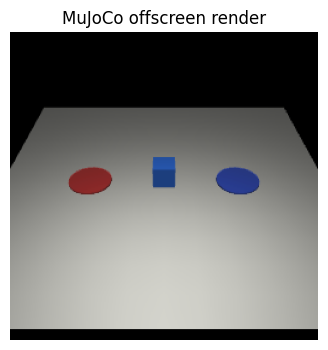

In [23]:
# 4. Direct MuJoCo physics + headless rendering smoke test
import mujoco

MUJOCO_XML = r"""
<mujoco model="robojepa_smoke">
  <option timestep="0.01" gravity="0 0 -9.81"/>
  <visual><global offwidth="256" offheight="256"/></visual>
  <worldbody>
    <light pos="0 -1 3" dir="0 0 -1"/>
    <camera name="fixed" pos="0 -2.2 1.7" xyaxes="1 0 0 0 0.62 0.78"/>
    <geom name="table" type="plane" size="1.2 1.2 0.1" rgba="0.78 0.78 0.75 1"/>
    <body name="cube" pos="0 0 0.08">
      <freejoint/>
      <geom type="box" size="0.08 0.08 0.08" mass="0.2" rgba="0.2 0.45 0.9 1"/>
    </body>
    <geom name="left_target" type="cylinder" pos="-0.55 0 0.006" size="0.16 0.006" rgba="0.9 0.15 0.15 0.45" contype="0" conaffinity="0"/>
    <geom name="right_target" type="cylinder" pos="0.55 0 0.006" size="0.16 0.006" rgba="0.15 0.3 0.95 0.45" contype="0" conaffinity="0"/>
  </worldbody>
</mujoco>
"""

try:
    mj_model = mujoco.MjModel.from_xml_string(MUJOCO_XML)
    mj_data = mujoco.MjData(mj_model)
    for _ in range(20):
        mujoco.mj_step(mj_model, mj_data)
    with mujoco.Renderer(mj_model, height=256, width=256) as renderer:
        renderer.update_scene(mj_data, camera="fixed")
        mujoco_frame = renderer.render().copy()
    assert mujoco_frame.shape == (256, 256, 3)
    imageio.imwrite(OUTPUT_DIR / "mujoco_smoke.png", mujoco_frame)
    plt.figure(figsize=(4, 4))
    plt.imshow(mujoco_frame)
    plt.title("MuJoCo offscreen render")
    plt.axis("off")
    plt.show()
    CHECKS["mujoco_render"] = {"passed": True, "shape": list(mujoco_frame.shape)}
except Exception as exc:
    CHECKS["mujoco_render"] = {"passed": False, "error": repr(exc)}
    print("MuJoCo smoke test failed; the synthetic pipeline can still run.")
    print(repr(exc))


In [24]:
# 5. robosuite environment, controller, step, and camera smoke test
import robosuite as suite

robo_env = None
try:
    robo_env = suite.make(
        env_name="Lift",
        robots="Panda",
        has_renderer=False,
        has_offscreen_renderer=True,
        use_camera_obs=True,
        camera_names="agentview",
        camera_heights=128,
        camera_widths=128,
        horizon=20,
        ignore_done=True,
        hard_reset=False,
    )
    observation = robo_env.reset()
    action_low, action_high = robo_env.action_spec
    neutral_action = np.clip(np.zeros_like(action_low), action_low, action_high)
    for _ in range(5):
        observation, reward, done, info = robo_env.step(neutral_action)

    camera_keys = [key for key in observation if key.endswith("_image")]
    assert camera_keys, f"No camera image found. Keys: {list(observation)}"
    robosuite_frame = np.asarray(observation[camera_keys[0]])[::-1].copy()
    imageio.imwrite(OUTPUT_DIR / "robosuite_smoke.png", robosuite_frame)

    plt.figure(figsize=(4, 4))
    plt.imshow(robosuite_frame)
    plt.title(f"robosuite Lift: {camera_keys[0]}")
    plt.axis("off")
    plt.show()
    CHECKS["robosuite_rollout"] = {
        "passed": True,
        "observation_key": camera_keys[0],
        "shape": list(robosuite_frame.shape),
        "action_dim": int(neutral_action.size),
    }
except Exception as exc:
    CHECKS["robosuite_rollout"] = {"passed": False, "error": repr(exc)}
    print("robosuite smoke test failed; inspect the compatibility report at the end.")
    print("The lightweight data/model pipeline will continue.")
    print(repr(exc))
finally:
    if robo_env is not None:
        robo_env.close()


[robosuite INFO] Loading controller configuration from: /usr/local/lib/python3.12/dist-packages/robosuite/controllers/config/robots/default_panda.json (composite_controller_factory.py:121)
INFO:robosuite_logs:Loading controller configuration from: /usr/local/lib/python3.12/dist-packages/robosuite/controllers/config/robots/default_panda.json


robosuite smoke test failed; inspect the compatibility report at the end.
The lightweight data/model pipeline will continue.
AssertionError()


## Tiny push-to-region dataset

Each starting scene has six bounded candidates: precise pushes toward each target, short pushes, an overshoot, and a missed-contact push. One simulated outcome is labeled against four instructions: left, right, red, and blue. This mirrors the proposal's requirement that the same outcome be judged under multiple language goals.

The target-color assignment swaps across scenes. Candidate outcomes are the trajectory unit; instruction rows are the supervised scoring unit.


In [25]:
# 6. Lightweight tabletop simulator and renderer
TABLE_X = (-1.0, 1.0)
TABLE_Y = (-0.62, 0.62)
TARGETS = {
    "left": np.array([-0.68, 0.0], dtype=np.float32),
    "right": np.array([0.68, 0.0], dtype=np.float32),
}
TARGET_RADIUS = 0.18
COLOR_RGB = {"red": (224, 68, 68), "blue": (55, 105, 225)}


def world_to_pixel(xy, size):
    x, y = float(xy[0]), float(xy[1])
    px = int(np.clip((x - TABLE_X[0]) / (TABLE_X[1] - TABLE_X[0]), 0, 1) * (size - 1))
    py = int((1 - np.clip((y - TABLE_Y[0]) / (TABLE_Y[1] - TABLE_Y[0]), 0, 1)) * (size - 1))
    return px, py


def render_table(cube_xy, side_to_color, size=96):
    image = Image.new("RGB", (size, size), (231, 225, 207))
    draw = ImageDraw.Draw(image)
    draw.rectangle((2, 2, size - 3, size - 3), outline=(95, 88, 78), width=2)

    for side, center in TARGETS.items():
        cx, cy = world_to_pixel(center, size)
        radius_px = max(5, int(TARGET_RADIUS / (TABLE_X[1] - TABLE_X[0]) * size))
        color = COLOR_RGB[side_to_color[side]]
        draw.ellipse(
            (cx - radius_px, cy - radius_px, cx + radius_px, cy + radius_px),
            fill=tuple(int(0.42 * c + 0.58 * 231) for c in color),
            outline=color,
            width=2,
        )

    cube_px = world_to_pixel(cube_xy, size)
    half = max(3, size // 24)
    draw.rounded_rectangle(
        (cube_px[0] - half, cube_px[1] - half, cube_px[0] + half, cube_px[1] + half),
        radius=2,
        fill=(55, 55, 60),
        outline=(245, 245, 245),
        width=1,
    )
    return np.asarray(image, dtype=np.uint8)


def simulate_push(start_xy, push_xy, contact_offset, rng):
    # A smooth contact model creates missed, partial, and successful pushes.
    contact_quality = float(np.clip(1.0 - (contact_offset / 0.14) ** 2, 0.0, 1.0))
    motion_noise = rng.normal(0.0, 0.008 + 0.018 * (1.0 - contact_quality), size=2)
    terminal = np.asarray(start_xy) + contact_quality * np.asarray(push_xy) + motion_noise
    terminal[0] = np.clip(terminal[0], TABLE_X[0] + 0.05, TABLE_X[1] - 0.05)
    terminal[1] = np.clip(terminal[1], TABLE_Y[0] + 0.05, TABLE_Y[1] - 0.05)
    return terminal.astype(np.float32), contact_quality


def inside_target(cube_xy, side):
    return float(np.linalg.norm(np.asarray(cube_xy) - TARGETS[side])) <= TARGET_RADIUS


def candidate_actions(start_xy, rng):
    to_left = TARGETS["left"] - start_xy
    to_right = TARGETS["right"] - start_xy
    overshoot_side = "left" if rng.random() < 0.5 else "right"
    overshoot_vector = TARGETS[overshoot_side] - start_xy
    return [
        ("precise_left", to_left + rng.normal(0, 0.006, 2), rng.uniform(0.0, 0.015), 1.00),
        ("precise_right", to_right + rng.normal(0, 0.006, 2), rng.uniform(0.0, 0.015), 1.00),
        ("short_left", 0.55 * to_left, rng.uniform(0.0, 0.025), 0.55),
        ("short_right", 0.55 * to_right, rng.uniform(0.0, 0.025), 0.55),
        (f"overshoot_{overshoot_side}", 1.38 * overshoot_vector, rng.uniform(0.0, 0.02), 1.38),
        ("missed_contact", rng.uniform([-0.8, -0.3], [0.8, 0.3]), rng.uniform(0.20, 0.28), 1.00),
    ]


In [26]:
# 7. Generate scene-grouped trajectories and instruction labels
rng = np.random.default_rng(CFG.seed)
scene_ids = np.array([f"scene_{idx:04d}" for idx in range(N_SCENES)])
shuffled_scene_ids = scene_ids.copy()
rng.shuffle(shuffled_scene_ids)
n_train = max(1, int(0.70 * N_SCENES))
n_val = max(1, int(0.15 * N_SCENES))
split_by_scene = {
    scene_id: (
        "train" if idx < n_train else
        "val" if idx < n_train + n_val else
        "test"
    )
    for idx, scene_id in enumerate(shuffled_scene_ids)
}

position_templates = {
    "train": "Move the cube to the {side} target.",
    "val": "Move the cube to the {side} target.",
    "test": "Guide the cube toward the zone on the {side}.",
}
color_templates = {
    "train": "Push the block into the {color} region.",
    "val": "Push the block into the {color} region.",
    "test": "Send the object to the {color} goal area.",
}

images = {}
candidate_records = []
instruction_records = []

for scene_number, scene_id in enumerate(tqdm(scene_ids, desc="Generating scenes")):
    split = split_by_scene[scene_id]
    start_xy = rng.uniform([-0.18, -0.12], [0.18, 0.12]).astype(np.float32)
    if rng.random() < 0.5:
        side_to_color = {"left": "red", "right": "blue"}
    else:
        side_to_color = {"left": "blue", "right": "red"}

    initial_image_id = f"{scene_id}_initial"
    images[initial_image_id] = render_table(start_xy, side_to_color, CFG.image_size)

    actions = candidate_actions(start_xy, rng)
    assert len(actions) == CFG.candidates_per_scene
    for candidate_number, (kind, push_xy, contact_offset, duration) in enumerate(actions):
        candidate_id = f"{scene_id}_candidate_{candidate_number:02d}"
        terminal_xy, contact_quality = simulate_push(start_xy, push_xy, contact_offset, rng)
        terminal_image_id = f"{candidate_id}_terminal"
        images[terminal_image_id] = render_table(terminal_xy, side_to_color, CFG.image_size)

        base = {
            "scene_id": scene_id,
            "candidate_id": candidate_id,
            "candidate_kind": kind,
            "split": split,
            "initial_image_id": initial_image_id,
            "terminal_image_id": terminal_image_id,
            "start_x": float(start_xy[0]),
            "start_y": float(start_xy[1]),
            "terminal_x": float(terminal_xy[0]),
            "terminal_y": float(terminal_xy[1]),
            "action_dx": float(push_xy[0]),
            "action_dy": float(push_xy[1]),
            "contact_offset": float(contact_offset),
            "duration": float(duration),
            "contact_quality": float(contact_quality),
            "left_color": side_to_color["left"],
            "right_color": side_to_color["right"],
            "success_left": int(inside_target(terminal_xy, "left")),
            "success_right": int(inside_target(terminal_xy, "right")),
        }
        candidate_records.append(base)

        for target_side in ("left", "right"):
            target_color = side_to_color[target_side]
            success = int(inside_target(terminal_xy, target_side))
            instruction_records.append({
                **base,
                "instruction_type": "position",
                "instruction": position_templates[split].format(side=target_side),
                "target_side": target_side,
                "target_color": target_color,
                "success": success,
            })
            instruction_records.append({
                **base,
                "instruction_type": "color",
                "instruction": color_templates[split].format(color=target_color),
                "target_side": target_side,
                "target_color": target_color,
                "success": success,
            })

candidate_df = pd.DataFrame(candidate_records)
rows_df = pd.DataFrame(instruction_records)

candidate_df.to_csv(OUTPUT_DIR / "candidate_trajectories.csv", index=False)
rows_df.to_csv(OUTPUT_DIR / "instruction_labeled_rows.csv", index=False)
image_ids = sorted(images)
np.savez_compressed(
    OUTPUT_DIR / "trajectory_images.npz",
    image_ids=np.asarray(image_ids),
    images=np.stack([images[image_id] for image_id in image_ids]),
)

CHECKS["dataset_generation"] = {
    "passed": True,
    "scenes": int(N_SCENES),
    "candidate_trajectories": int(len(candidate_df)),
    "instruction_rows": int(len(rows_df)),
    "images": int(len(images)),
}
print(json.dumps(CHECKS["dataset_generation"], indent=2))
display(rows_df.head())


Generating scenes:   0%|          | 0/24 [00:00<?, ?it/s]

{
  "passed": true,
  "scenes": 24,
  "candidate_trajectories": 144,
  "instruction_rows": 576,
  "images": 168
}


,scene_id,candidate_id,candidate_kind,split,initial_image_id,terminal_image_id,start_x,start_y,terminal_x,terminal_y,...,contact_quality,left_color,right_color,success_left,success_right,instruction_type,instruction,target_side,target_color,success
0,scene_0000,scene_0000_candidate_00,precise_left,test,scene_0000_initial,scene_0000_candidate_00_terminal,0.071609,0.08147,-0.683032,0.011072,...,0.999145,blue,red,1,0,position,Guide the cube toward the zone on the left.,left,blue,1
1,scene_0000,scene_0000_candidate_00,precise_left,test,scene_0000_initial,scene_0000_candidate_00_terminal,0.071609,0.08147,-0.683032,0.011072,...,0.999145,blue,red,1,0,color,Send the object to the blue goal area.,left,blue,1
2,scene_0000,scene_0000_candidate_00,precise_left,test,scene_0000_initial,scene_0000_candidate_00_terminal,0.071609,0.08147,-0.683032,0.011072,...,0.999145,blue,red,1,0,position,Guide the cube toward the zone on the right.,right,red,0
3,scene_0000,scene_0000_candidate_00,precise_left,test,scene_0000_initial,scene_0000_candidate_00_terminal,0.071609,0.08147,-0.683032,0.011072,...,0.999145,blue,red,1,0,color,Send the object to the red goal area.,right,red,0
4,scene_0000,scene_0000_candidate_01,precise_right,test,scene_0000_initial,scene_0000_candidate_01_terminal,0.071609,0.08147,0.655483,-0.019107,...,0.993077,blue,red,0,1,position,Guide the cube toward the zone on the left.,left,blue,0


count  positive_rate  positives
split instruction_type                                 
test  color                60       0.166667         10
      position             60       0.166667         10
train color               192       0.166667         32
      position            192       0.166667         32
val   color                36       0.166667          6
      position             36       0.166667          6

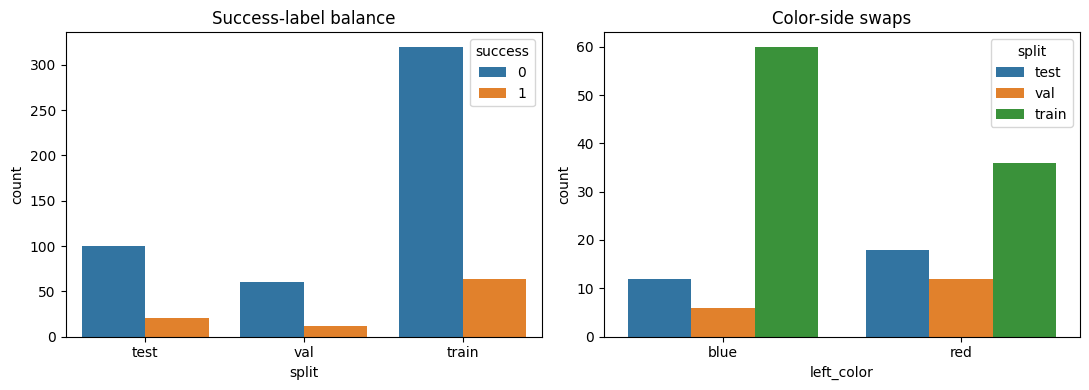

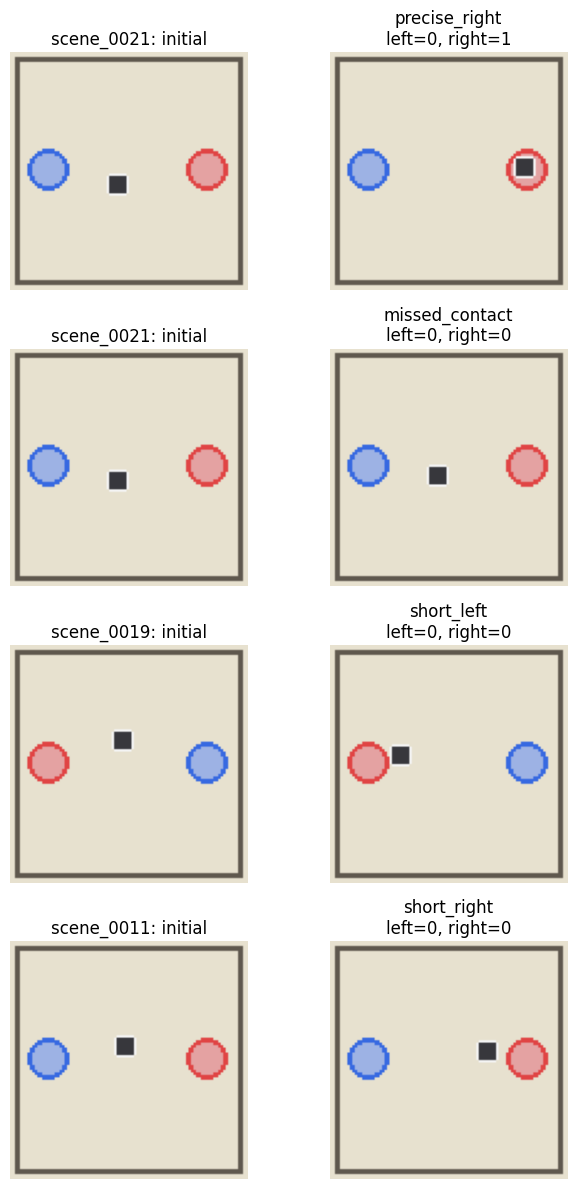

In [27]:
# 8. Dataset validation: leakage, balance, target swaps, and visual samples
scene_sets = {
    split: set(rows_df.loc[rows_df["split"] == split, "scene_id"])
    for split in ("train", "val", "test")
}
assert scene_sets["train"].isdisjoint(scene_sets["val"])
assert scene_sets["train"].isdisjoint(scene_sets["test"])
assert scene_sets["val"].isdisjoint(scene_sets["test"])
assert rows_df.groupby("candidate_id")["split"].nunique().max() == 1
assert rows_df.groupby("scene_id")["split"].nunique().max() == 1
assert set(rows_df.loc[rows_df["split"] == "test", "instruction"]).isdisjoint(
    set(rows_df.loc[rows_df["split"] == "train", "instruction"])
)
assert set(candidate_df["left_color"]) == {"red", "blue"}

summary = (
    rows_df.groupby(["split", "instruction_type"])["success"]
    .agg(["count", "mean", "sum"])
    .rename(columns={"mean": "positive_rate", "sum": "positives"})
)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=rows_df, x="split", hue="success", ax=axes[0])
axes[0].set_title("Success-label balance")
sns.countplot(data=candidate_df, x="left_color", hue="split", ax=axes[1])
axes[1].set_title("Color-side swaps")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "dataset_balance.png", dpi=160, bbox_inches="tight")
plt.show()

sample_candidates = candidate_df.sample(min(4, len(candidate_df)), random_state=CFG.seed)
fig, axes = plt.subplots(len(sample_candidates), 2, figsize=(7, 3 * len(sample_candidates)))
axes = np.atleast_2d(axes)
for row_index, (_, row) in enumerate(sample_candidates.iterrows()):
    axes[row_index, 0].imshow(images[row.initial_image_id])
    axes[row_index, 0].set_title(f"{row.scene_id}: initial")
    axes[row_index, 1].imshow(images[row.terminal_image_id])
    axes[row_index, 1].set_title(
        f"{row.candidate_kind}\nleft={row.success_left}, right={row.success_right}"
    )
    axes[row_index, 0].axis("off")
    axes[row_index, 1].axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "trajectory_examples.png", dpi=160, bbox_inches="tight")
plt.show()

CHECKS["dataset_validation"] = {
    "passed": True,
    "train_scenes": len(scene_sets["train"]),
    "val_scenes": len(scene_sets["val"]),
    "test_scenes": len(scene_sets["test"]),
    "heldout_test_paraphrases": True,
}


## Frozen feature encoders

The primary path uses `dinov2_vits14` from Meta's official PyTorch Hub and `all-MiniLM-L6-v2` from Sentence Transformers. Both encoders remain frozen while their features are cached. If either download fails, the notebook records the error and uses a deterministic projection or hashing fallback so the rest of the compatibility test still completes.

The fallback proves plumbing only; use the compatibility report to confirm whether the intended pretrained encoders were actually exercised.


In [28]:
# 9. Load frozen visual and text encoders with explicit offline fallbacks
from sklearn.feature_extraction.text import HashingVectorizer

vision_encoder = None
vision_encoder_name = None
vision_fallback_projection = None

if CFG.use_pretrained_encoders:
    try:
        vision_encoder = torch.hub.load(
            "facebookresearch/dinov2",
            "dinov2_vits14",
            trust_repo=True,
        ).to(DEVICE).eval()
        for parameter in vision_encoder.parameters():
            parameter.requires_grad = False
        vision_encoder_name = "dinov2_vits14"
        CHECKS["visual_encoder"] = {"passed": True, "name": vision_encoder_name}
    except Exception as exc:
        CHECKS["visual_encoder"] = {
            "passed": False,
            "requested": "dinov2_vits14",
            "error": repr(exc),
            "fallback": "deterministic_random_projection",
        }

if vision_encoder is None:
    projection_rng = np.random.default_rng(CFG.seed)
    vision_fallback_projection = projection_rng.normal(
        0.0, 1.0 / math.sqrt(3 * 32 * 32), size=(3 * 32 * 32, 128)
    ).astype(np.float32)
    vision_encoder_name = "deterministic_random_projection"


def preprocess_images(np_batch, size=224):
    tensor = torch.from_numpy(np.stack(np_batch)).float().permute(0, 3, 1, 2) / 255.0
    tensor = F.interpolate(tensor, size=(size, size), mode="bilinear", align_corners=False)
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    return (tensor - mean) / std


def encode_images(image_id_list, batch_size=32):
    all_features = []
    for start in tqdm(range(0, len(image_id_list), batch_size), desc="Visual features"):
        batch_ids = image_id_list[start:start + batch_size]
        batch_images = [images[image_id] for image_id in batch_ids]
        if vision_encoder is not None:
            batch = preprocess_images(batch_images).to(DEVICE)
            with torch.inference_mode(), torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda"),
            ):
                features = vision_encoder(batch)
            features = F.normalize(features.float(), dim=-1).cpu().numpy()
        else:
            batch = preprocess_images(batch_images, size=32).reshape(len(batch_images), -1).numpy()
            features = batch @ vision_fallback_projection
            features /= np.maximum(np.linalg.norm(features, axis=1, keepdims=True), 1e-8)
        all_features.append(features.astype(np.float32))
    return np.concatenate(all_features, axis=0)


visual_feature_matrix = encode_images(image_ids)
visual_feature_by_id = dict(zip(image_ids, visual_feature_matrix))

unique_instructions = sorted(rows_df["instruction"].unique())
text_encoder_name = None
try:
    if not CFG.use_pretrained_encoders:
        raise RuntimeError("Pretrained encoders disabled in Config")
    from sentence_transformers import SentenceTransformer

    text_encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=str(DEVICE))
    text_feature_matrix = text_encoder.encode(
        unique_instructions,
        batch_size=32,
        show_progress_bar=False,
        convert_to_numpy=True,
        normalize_embeddings=True,
    ).astype(np.float32)
    text_encoder_name = "sentence-transformers/all-MiniLM-L6-v2"
    CHECKS["text_encoder"] = {"passed": True, "name": text_encoder_name}
except Exception as exc:
    vectorizer = HashingVectorizer(
        n_features=256,
        alternate_sign=False,
        norm="l2",
        ngram_range=(1, 2),
    )
    text_feature_matrix = vectorizer.transform(unique_instructions).toarray().astype(np.float32)
    text_encoder_name = "hashing_vectorizer_fallback"
    CHECKS["text_encoder"] = {
        "passed": False,
        "requested": "sentence-transformers/all-MiniLM-L6-v2",
        "error": repr(exc),
        "fallback": text_encoder_name,
    }

text_feature_by_instruction = dict(zip(unique_instructions, text_feature_matrix))
np.savez_compressed(
    OUTPUT_DIR / "cached_features.npz",
    image_ids=np.asarray(image_ids),
    visual_features=visual_feature_matrix,
    instructions=np.asarray(unique_instructions),
    text_features=text_feature_matrix,
)

VISUAL_DIM = int(visual_feature_matrix.shape[1])
TEXT_DIM = int(text_feature_matrix.shape[1])
ACTION_COLUMNS = ["action_dx", "action_dy", "contact_offset", "duration"]
print({
    "visual_encoder": vision_encoder_name,
    "visual_dim": VISUAL_DIM,
    "text_encoder": text_encoder_name,
    "text_dim": TEXT_DIM,
})


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Visual features:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'visual_encoder': 'dinov2_vits14', 'visual_dim': 384, 'text_encoder': 'sentence-transformers/all-MiniLM-L6-v2', 'text_dim': 384}


## Initial models

- **Direct classifier:** current visual feature + candidate action + instruction embedding -> success logit.
- **Action-conditioned predictor:** current visual feature + candidate action -> predicted terminal visual feature.
- **Instruction-conditioned scorer:** actual terminal visual feature + instruction embedding -> success logit.

At evaluation time, the scorer receives both actual terminal features (oracle diagnostic) and predictor-generated terminal features (JEPA path). DINOv2 and the text encoder stay frozen; the compact project-specific networks are fine-tuned on the generated dataset.


In [29]:
# 10. Assemble feature arrays without crossing scene splits
train_actions = rows_df.loc[rows_df["split"] == "train", ACTION_COLUMNS].to_numpy(np.float32)
action_mean = train_actions.mean(axis=0)
action_std = train_actions.std(axis=0)
action_std[action_std < 1e-6] = 1.0


def normalized_actions(frame):
    raw = frame[ACTION_COLUMNS].to_numpy(np.float32)
    return ((raw - action_mean) / action_std).astype(np.float32)


def row_feature_arrays(frame):
    initial = np.stack([visual_feature_by_id[x] for x in frame["initial_image_id"]])
    terminal = np.stack([visual_feature_by_id[x] for x in frame["terminal_image_id"]])
    text = np.stack([text_feature_by_instruction[x] for x in frame["instruction"]])
    action = normalized_actions(frame)
    label = frame["success"].to_numpy(np.float32)
    return initial, terminal, action, text, label


def candidate_feature_arrays(frame):
    initial = np.stack([visual_feature_by_id[x] for x in frame["initial_image_id"]])
    terminal = np.stack([visual_feature_by_id[x] for x in frame["terminal_image_id"]])
    action = normalized_actions(frame)
    return initial, terminal, action


row_arrays = {
    split: row_feature_arrays(rows_df[rows_df["split"] == split].reset_index(drop=True))
    for split in ("train", "val", "test")
}
candidate_arrays = {
    split: candidate_feature_arrays(candidate_df[candidate_df["split"] == split].reset_index(drop=True))
    for split in ("train", "val", "test")
}

print({
    split: {
        "instruction_rows": int((rows_df["split"] == split).sum()),
        "candidate_trajectories": int((candidate_df["split"] == split).sum()),
    }
    for split in ("train", "val", "test")
})


{'train': {'instruction_rows': 384, 'candidate_trajectories': 96}, 'val': {'instruction_rows': 72, 'candidate_trajectories': 18}, 'test': {'instruction_rows': 120, 'candidate_trajectories': 30}}


In [30]:
# 11. Model definitions and training utilities
class MLP(nn.Module):
    def __init__(self, input_dim, output_dim, hidden_dim=256, dropout=0.10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, output_dim),
        )

    def forward(self, x):
        return self.net(x)


def make_loader(*arrays, shuffle, batch_size=CFG.batch_size):
    tensors = [torch.from_numpy(np.asarray(array)).float() for array in arrays]
    return DataLoader(
        TensorDataset(*tensors),
        batch_size=min(batch_size, len(tensors[0])),
        shuffle=shuffle,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda"),
    )


def predict_numpy(model, features, batch_size=512):
    model.eval()
    outputs = []
    with torch.inference_mode():
        for start in range(0, len(features), batch_size):
            batch = torch.from_numpy(features[start:start + batch_size]).float().to(DEVICE)
            outputs.append(model(batch).float().cpu().numpy())
    return np.concatenate(outputs, axis=0)


def safe_auc(y_true, probabilities):
    return float(roc_auc_score(y_true, probabilities)) if len(np.unique(y_true)) > 1 else float("nan")


def train_classifier(name, model, train_x, train_y, val_x, val_y, epochs=EPOCHS):
    model = model.to(DEVICE)
    positives = max(float(train_y.sum()), 1.0)
    negatives = max(float(len(train_y) - train_y.sum()), 1.0)
    pos_weight = torch.tensor([negatives / positives], device=DEVICE)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
    loader = make_loader(train_x, train_y[:, None], shuffle=True)
    history = []
    best_state = None
    best_val = float("inf")

    for epoch in range(1, epochs + 1):
        model.train()
        losses = []
        for features, labels in loader:
            features, labels = features.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(features)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        model.eval()
        with torch.inference_mode():
            val_features = torch.from_numpy(val_x).float().to(DEVICE)
            val_labels = torch.from_numpy(val_y[:, None]).float().to(DEVICE)
            val_logits = model(val_features)
            val_loss = float(criterion(val_logits, val_labels).cpu())
            val_probabilities = torch.sigmoid(val_logits).cpu().numpy().ravel()
        history.append({
            "model": name,
            "epoch": epoch,
            "train_loss": float(np.mean(losses)),
            "val_loss": val_loss,
            "val_auc": safe_auc(val_y, val_probabilities),
        })
        if val_loss < best_val:
            best_val = val_loss
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)


def train_predictor(model, train_initial, train_action, train_terminal,
                    val_initial, val_action, val_terminal, epochs=EPOCHS):
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
    train_x = np.concatenate([train_initial, train_action], axis=1).astype(np.float32)
    val_x = np.concatenate([val_initial, val_action], axis=1).astype(np.float32)
    loader = make_loader(train_x, train_terminal, shuffle=True)
    history = []
    best_state = None
    best_val = float("inf")

    for epoch in range(1, epochs + 1):
        model.train()
        losses = []
        for features, target in loader:
            features, target = features.to(DEVICE), target.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction = F.normalize(model(features), dim=-1)
            loss = 0.70 * (1.0 - F.cosine_similarity(prediction, target, dim=-1)).mean()
            loss = loss + 0.30 * F.mse_loss(prediction, target)
            loss.backward()
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        model.eval()
        with torch.inference_mode():
            val_features = torch.from_numpy(val_x).float().to(DEVICE)
            val_target = torch.from_numpy(val_terminal).float().to(DEVICE)
            val_prediction = F.normalize(model(val_features), dim=-1)
            val_loss = 0.70 * (1.0 - F.cosine_similarity(val_prediction, val_target, dim=-1)).mean()
            val_loss = val_loss + 0.30 * F.mse_loss(val_prediction, val_target)
            val_loss_value = float(val_loss.cpu())
        history.append({
            "model": "jepa_predictor",
            "epoch": epoch,
            "train_loss": float(np.mean(losses)),
            "val_loss": val_loss_value,
            "val_auc": np.nan,
        })
        if val_loss_value < best_val:
            best_val = val_loss_value
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)


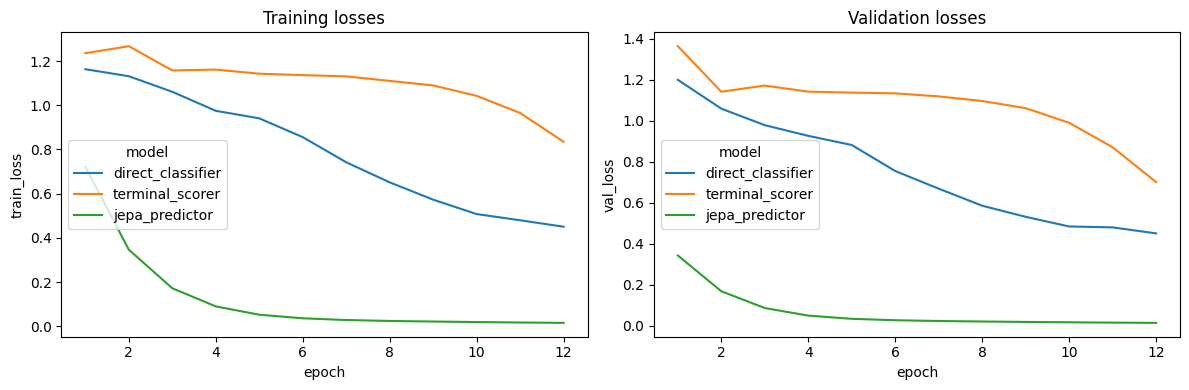

In [31]:
# 12. Fine-tune the compact heads and action-conditioned predictor
train_initial, train_terminal, train_action, train_text, train_y = row_arrays["train"]
val_initial, val_terminal, val_action, val_text, val_y = row_arrays["val"]

direct_train_x = np.concatenate([train_initial, train_action, train_text], axis=1).astype(np.float32)
direct_val_x = np.concatenate([val_initial, val_action, val_text], axis=1).astype(np.float32)
scorer_train_x = np.concatenate([train_terminal, train_text], axis=1).astype(np.float32)
scorer_val_x = np.concatenate([val_terminal, val_text], axis=1).astype(np.float32)

direct_model = MLP(VISUAL_DIM + len(ACTION_COLUMNS) + TEXT_DIM, 1)
scorer_model = MLP(VISUAL_DIM + TEXT_DIM, 1)
predictor_model = MLP(VISUAL_DIM + len(ACTION_COLUMNS), VISUAL_DIM)

direct_model, direct_history = train_classifier(
    "direct_classifier", direct_model,
    direct_train_x, train_y, direct_val_x, val_y,
)
scorer_model, scorer_history = train_classifier(
    "terminal_scorer", scorer_model,
    scorer_train_x, train_y, scorer_val_x, val_y,
)

pred_train_initial, pred_train_terminal, pred_train_action = candidate_arrays["train"]
pred_val_initial, pred_val_terminal, pred_val_action = candidate_arrays["val"]
predictor_model, predictor_history = train_predictor(
    predictor_model,
    pred_train_initial, pred_train_action, pred_train_terminal,
    pred_val_initial, pred_val_action, pred_val_terminal,
)

training_history = pd.concat(
    [direct_history, scorer_history, predictor_history], ignore_index=True
)
training_history.to_csv(OUTPUT_DIR / "training_curves.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=training_history, x="epoch", y="train_loss", hue="model", ax=axes[0])
axes[0].set_title("Training losses")
sns.lineplot(data=training_history, x="epoch", y="val_loss", hue="model", ax=axes[1])
axes[1].set_title("Validation losses")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "learning_curves.png", dpi=160, bbox_inches="tight")
plt.show()

CHECKS["model_training"] = {
    "passed": True,
    "epochs": EPOCHS,
    "models": ["direct_classifier", "jepa_predictor", "terminal_scorer"],
}


## Offline action-ranking comparison

For each test instruction, every method sees the same six candidate actions and no hidden target coordinates.

- **Direct:** scores current image + action + instruction.
- **JEPA:** predicts a terminal image feature from current image + action, then scores it with the instruction.
- **Oracle scorer:** scores the feature extracted from the actual terminal image. This diagnoses scorer error separately from world-model error.

Selected-action success is the main tiny-dataset ranking metric. Predictor cosine error and per-candidate latency are also reported.


{
  "direct_candidate_auc": 0.8975000000000001,
  "direct_candidate_accuracy_at_0_5": 0.8333333333333334,
  "oracle_scorer_candidate_auc": 0.901,
  "jepa_candidate_auc": 0.673,
  "predictor_mean_cosine_error": 0.019649427384138107,
  "direct_action_selection_success": 0.5,
  "jepa_action_selection_success": 0.0,
  "oracle_action_selection_success": 0.5,
  "direct_latency_ms_per_candidate": 0.004207840833222083,
  "jepa_latency_ms_per_candidate": 0.009378847500064088,
  "test_decisions": 20
}


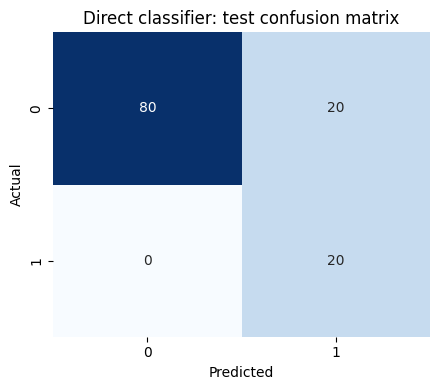

In [32]:
# 13. Evaluate classification, prediction quality, ranking, and latency
test_rows = rows_df[rows_df["split"] == "test"].reset_index(drop=True).copy()
test_initial, test_terminal, test_action, test_text, test_y = row_arrays["test"]

direct_test_x = np.concatenate([test_initial, test_action, test_text], axis=1).astype(np.float32)
oracle_scorer_x = np.concatenate([test_terminal, test_text], axis=1).astype(np.float32)

direct_logits = predict_numpy(direct_model, direct_test_x).ravel()
oracle_logits = predict_numpy(scorer_model, oracle_scorer_x).ravel()
predicted_terminal = predict_numpy(
    predictor_model,
    np.concatenate([test_initial, test_action], axis=1).astype(np.float32),
)
predicted_terminal /= np.maximum(np.linalg.norm(predicted_terminal, axis=1, keepdims=True), 1e-8)
jepa_logits = predict_numpy(
    scorer_model,
    np.concatenate([predicted_terminal, test_text], axis=1).astype(np.float32),
).ravel()

test_rows["direct_score"] = 1.0 / (1.0 + np.exp(-direct_logits))
test_rows["jepa_score"] = 1.0 / (1.0 + np.exp(-jepa_logits))
test_rows["oracle_score"] = 1.0 / (1.0 + np.exp(-oracle_logits))

ranking_keys = ["scene_id", "instruction", "target_side", "instruction_type"]


def selected_action_metrics(frame, score_column):
    selected_indices = frame.groupby(ranking_keys, sort=False)[score_column].idxmax()
    selected = frame.loc[selected_indices].copy()
    return {
        "selected_action_success": float(selected["success"].mean()),
        "decisions": int(len(selected)),
    }, selected


direct_ranking, direct_selected = selected_action_metrics(test_rows, "direct_score")
jepa_ranking, jepa_selected = selected_action_metrics(test_rows, "jepa_score")
oracle_ranking, oracle_selected = selected_action_metrics(test_rows, "oracle_score")

unique_test_candidates = candidate_df[candidate_df["split"] == "test"].reset_index(drop=True)
u_initial, u_terminal, u_action = candidate_feature_arrays(unique_test_candidates)
u_prediction = predict_numpy(
    predictor_model,
    np.concatenate([u_initial, u_action], axis=1).astype(np.float32),
)
u_prediction /= np.maximum(np.linalg.norm(u_prediction, axis=1, keepdims=True), 1e-8)
predictor_cosine_error = float(
    np.mean(1.0 - np.sum(u_prediction * u_terminal, axis=1))
)


def benchmark_ms_per_candidate(function, repeats=20):
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(repeats):
        function()
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return 1000.0 * (time.perf_counter() - start) / (repeats * len(test_rows))


direct_latency = benchmark_ms_per_candidate(
    lambda: predict_numpy(direct_model, direct_test_x)
)
jepa_latency = benchmark_ms_per_candidate(
    lambda: predict_numpy(
        scorer_model,
        np.concatenate([
            predict_numpy(
                predictor_model,
                np.concatenate([test_initial, test_action], axis=1).astype(np.float32),
            ),
            test_text,
        ], axis=1).astype(np.float32),
    ),
)

metrics = {
    "direct_candidate_auc": safe_auc(test_y, test_rows["direct_score"].to_numpy()),
    "direct_candidate_accuracy_at_0_5": float(
        accuracy_score(test_y, test_rows["direct_score"].to_numpy() >= 0.5)
    ),
    "oracle_scorer_candidate_auc": safe_auc(test_y, test_rows["oracle_score"].to_numpy()),
    "jepa_candidate_auc": safe_auc(test_y, test_rows["jepa_score"].to_numpy()),
    "predictor_mean_cosine_error": predictor_cosine_error,
    "direct_action_selection_success": direct_ranking["selected_action_success"],
    "jepa_action_selection_success": jepa_ranking["selected_action_success"],
    "oracle_action_selection_success": oracle_ranking["selected_action_success"],
    "direct_latency_ms_per_candidate": direct_latency,
    "jepa_latency_ms_per_candidate": jepa_latency,
    "test_decisions": direct_ranking["decisions"],
}
print(json.dumps(metrics, indent=2))

selected_actions = pd.concat([
    direct_selected.assign(method="direct"),
    jepa_selected.assign(method="jepa"),
    oracle_selected.assign(method="oracle_terminal"),
], ignore_index=True)
selected_actions.to_csv(OUTPUT_DIR / "selected_actions.csv", index=False)

cm = confusion_matrix(test_y, test_rows["direct_score"].to_numpy() >= 0.5)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Direct classifier: test confusion matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "direct_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

CHECKS["offline_action_ranking"] = {
    "passed": True,
    "test_decisions": direct_ranking["decisions"],
}


## Optional tiny DINOv2 last-block fine-tuning check

The baseline above freezes DINOv2, as specified in the proposal. To verify that gradient-based visual fine-tuning also fits the runtime, set `run_visual_last_block_finetune=True` in `Config` and rerun from the configuration cell.

This isolated one-epoch check unfreezes only DINOv2's last transformer block, uses at most 128 training rows, and saves a separate checkpoint. It does **not** silently change the cached-feature baseline metrics above.


In [33]:
# 14. Optional: one tiny last-block DINOv2 fine-tuning epoch
if CFG.run_visual_last_block_finetune:
    if vision_encoder_name != "dinov2_vits14" or vision_encoder is None:
        raise RuntimeError("The optional fine-tune check requires the DINOv2 primary path.")

    for parameter in vision_encoder.parameters():
        parameter.requires_grad = False
    for parameter in vision_encoder.blocks[-1].parameters():
        parameter.requires_grad = True
    vision_encoder.train()

    finetune_head = MLP(VISUAL_DIM + len(ACTION_COLUMNS) + TEXT_DIM, 1).to(DEVICE)
    trainable = [p for p in vision_encoder.parameters() if p.requires_grad]
    trainable += list(finetune_head.parameters())
    optimizer = torch.optim.AdamW(trainable, lr=2e-5, weight_decay=1e-4)
    criterion = nn.BCEWithLogitsLoss()

    finetune_rows = rows_df[rows_df["split"] == "train"].sample(
        min(128, int((rows_df["split"] == "train").sum())),
        random_state=CFG.seed,
    ).reset_index(drop=True)

    finetune_losses = []
    for start in tqdm(range(0, len(finetune_rows), 8), desc="DINOv2 last-block check"):
        batch = finetune_rows.iloc[start:start + 8]
        pixel_values = preprocess_images(
            [images[x] for x in batch["initial_image_id"]]
        ).to(DEVICE)
        action_features = torch.from_numpy(normalized_actions(batch)).float().to(DEVICE)
        text_features = torch.from_numpy(np.stack([
            text_feature_by_instruction[x] for x in batch["instruction"]
        ])).float().to(DEVICE)
        labels = torch.from_numpy(batch["success"].to_numpy(np.float32)[:, None]).to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        visual_features = F.normalize(vision_encoder(pixel_values).float(), dim=-1)
        logits = finetune_head(torch.cat([visual_features, action_features, text_features], dim=1))
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        finetune_losses.append(float(loss.detach().cpu()))

    torch.save({
        "dinov2_last_block": vision_encoder.blocks[-1].state_dict(),
        "finetune_head": finetune_head.state_dict(),
        "mean_loss": float(np.mean(finetune_losses)),
    }, OUTPUT_DIR / "optional_dinov2_last_block_check.pt")
    vision_encoder.eval()
    CHECKS["optional_visual_finetune"] = {
        "passed": True,
        "rows": len(finetune_rows),
        "mean_loss": float(np.mean(finetune_losses)),
    }
    print(CHECKS["optional_visual_finetune"])
else:
    CHECKS["optional_visual_finetune"] = {
        "passed": None,
        "skipped": True,
        "reason": "Disabled by default; set Config.run_visual_last_block_finetune=True.",
    }
    print(CHECKS["optional_visual_finetune"])


{'passed': None, 'skipped': True, 'reason': 'Disabled by default; set Config.run_visual_last_block_finetune=True.'}


In [34]:
# 15. Save checkpoints, metrics, configuration, and the final compatibility report
checkpoint = {
    "config": asdict(CFG),
    "visual_encoder": vision_encoder_name,
    "text_encoder": text_encoder_name,
    "visual_dim": VISUAL_DIM,
    "text_dim": TEXT_DIM,
    "action_columns": ACTION_COLUMNS,
    "action_mean": action_mean,
    "action_std": action_std,
    "direct_model": direct_model.state_dict(),
    "predictor_model": predictor_model.state_dict(),
    "scorer_model": scorer_model.state_dict(),
}
torch.save(checkpoint, OUTPUT_DIR / "robojepa_tiny_baselines.pt")

with (OUTPUT_DIR / "metrics.json").open("w") as file:
    json.dump(metrics, file, indent=2)

with (OUTPUT_DIR / "config.json").open("w") as file:
    json.dump(asdict(CFG), file, indent=2)

compatibility_report = {
    "runtime": runtime,
    "checks": CHECKS,
    "encoders_used": {
        "visual": vision_encoder_name,
        "text": text_encoder_name,
    },
    "dataset": CHECKS["dataset_generation"],
    "metrics": metrics,
    "limitations": [
        "Colab exercises NVIDIA/CUDA, not the local AMD RX 9070 XT/ROCm stack.",
        "The tiny 2-D generator bootstraps data/model plumbing; it is not the final custom robosuite task.",
        "Closed-loop robot control is intentionally left for the next milestone.",
    ],
}
with (OUTPUT_DIR / "compatibility_report.json").open("w") as file:
    json.dump(compatibility_report, file, indent=2, default=str)

archive_path = shutil.make_archive(
    str(OUTPUT_DIR.parent / "robojepa_outputs"), "zip", root_dir=OUTPUT_DIR
)

print("Saved files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"- {path.name}: {path.stat().st_size / 1024:.1f} KiB")
print("Archive:", archive_path)
print("\nCompatibility summary:")
for name, result in CHECKS.items():
    print(f"- {name}: {result.get('passed')}")


Saved files:
- cached_features.npz: 224.1 KiB
- candidate_trajectories.csv: 40.0 KiB
- compatibility_report.json: 3.0 KiB
- config.json: 0.3 KiB
- dataset_balance.png: 43.5 KiB
- direct_confusion_matrix.png: 18.8 KiB
- instruction_labeled_rows.csv: 191.0 KiB
- learning_curves.png: 93.4 KiB
- metrics.json: 0.5 KiB
- mujoco_smoke.png: 12.8 KiB
- robojepa_tiny_baselines.pt: 3105.5 KiB
- selected_actions.csv: 23.0 KiB
- training_curves.csv: 2.5 KiB
- trajectory_examples.png: 53.3 KiB
- trajectory_images.npz: 35.3 KiB
Archive: /content/robojepa_outputs.zip

Compatibility summary:
- torch_tensor_grad: True
- dataloader: True
- gpu: True
- mujoco_render: True
- robosuite_rollout: False
- dataset_generation: True
- dataset_validation: True
- visual_encoder: True
- text_encoder: True
- model_training: True
- offline_action_ranking: True
- optional_visual_finetune: None


In [35]:
# 16. Optional Colab download
# Uncomment the final two lines after the run if you want the ZIP downloaded immediately.
# from google.colab import files
# files.download(str(OUTPUT_DIR.parent / "robojepa_outputs.zip"))


## Pass criteria and next milestone

The bootstrap run passes when it:

- exercises PyTorch tensors and gradients on the selected device;
- renders with MuJoCo and steps/renders a robosuite environment;
- creates reproducible scene-grouped data with held-out paraphrases;
- loads the intended frozen encoders (or clearly reports a fallback);
- trains all three compact models without errors;
- produces direct, JEPA, and oracle action-ranking metrics;
- saves a checkpoint and compatibility report.

After the first successful run, the next engineering step is to replace the lightweight generator with a custom robosuite push-to-region environment while preserving the CSV schema, cached-feature interface, split rules, and evaluation functions in this notebook.
